In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("amazon_cleaned.csv")

print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df[["review_title", "review_content", "rating"]].isnull().sum())

print("\nFirst Review Title:")
print(df["review_title"].iloc[0])

print("\nFirst Review Content:")
print(df["review_content"].iloc[0])

print("\nData Types:")
print(df[["review_title", "review_content", "rating"]].dtypes)

Dataset Shape: (1348, 18)

Missing Values:
review_title      0
review_content    0
rating            0
dtype: int64

First Review Title:
Satisfied,Charging is really fast,Value for money,Product review,Good quality,Good product,Good Product,As of now seems good

First Review Content:
Looks durable Charging is fine tooNo complains,Charging is really fast, good product.,Till now satisfied with the quality.,This is a good product . The charging speed is slower than the original iPhone cable,Good quality, would recommend,https://m.media-amazon.com/images/W/WEBP_402378-T1/images/I/81---F1ZgHL._SY88.jpg,Product had worked well till date and was having no issue.Cable is also sturdy enough...Have asked for replacement and company is doing the same...,Value for money

Data Types:
review_title          str
review_content        str
rating            float64
dtype: object


In [2]:
#removing URLs
import re
import html

def clean_review(text):
    if pd.isna(text):
        return ""

    text = html.unescape(str(text))
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = text.lower()
    text = re.sub(r"[^a-z0-9\s.,!?']", " ", text)
    text = re.sub(r"\s+", " ", text).strip()

    return text

df["clean_review_title"] = df["review_title"].apply(clean_review)
df["clean_review_content"] = df["review_content"].apply(clean_review)

print("ORIGINAL REVIEW:")
print(df["review_content"].iloc[0])

print("\nCLEANED REVIEW:")
print(df["clean_review_content"].iloc[0])

print("\nMissing/Empty Cleaned Reviews:")
print((df["clean_review_content"] == "").sum())

ORIGINAL REVIEW:
Looks durable Charging is fine tooNo complains,Charging is really fast, good product.,Till now satisfied with the quality.,This is a good product . The charging speed is slower than the original iPhone cable,Good quality, would recommend,https://m.media-amazon.com/images/W/WEBP_402378-T1/images/I/81---F1ZgHL._SY88.jpg,Product had worked well till date and was having no issue.Cable is also sturdy enough...Have asked for replacement and company is doing the same...,Value for money

CLEANED REVIEW:
looks durable charging is fine toono complains,charging is really fast, good product.,till now satisfied with the quality.,this is a good product . the charging speed is slower than the original iphone cable,good quality, would recommend, had worked well till date and was having no issue.cable is also sturdy enough...have asked for replacement and company is doing the same...,value for money

Missing/Empty Cleaned Reviews:
0


In [5]:
#sentimentanalysis using vader
%pip install vadersentiment
print("vadersentiment installed successfully")

Note: you may need to restart the kernel to use updated packages.
vadersentiment installed successfully


In [2]:
import pandas as pd
import re
import html
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

df = pd.read_csv("amazon_cleaned.csv")

analyzer = SentimentIntensityAnalyzer()

# Clean text without removing sentiment-related punctuation or capitals
def clean_for_sentiment(text):
    if pd.isna(text):
        return ""

    text = html.unescape(str(text))
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\s+", " ", text).strip()

    return text

# Clean review title and content
df["clean_review_title"] = df["review_title"].apply(clean_for_sentiment)
df["clean_review_content"] = df["review_content"].apply(clean_for_sentiment)

# Combine review title and content
df["review_text"] = (
    df["clean_review_title"] + ". " +
    df["clean_review_content"]
).str.strip()

# Calculate sentiment scores
df["sentiment_score"] = df["review_text"].apply(
    lambda text: analyzer.polarity_scores(text)["compound"]
)

# Classify sentiment
def classify_sentiment(score):
    if score >= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    else:
        return "Neutral"

df["sentiment"] = df["sentiment_score"].apply(classify_sentiment)

print(df[["product_name", "rating", "sentiment_score", "sentiment"]].head())

print("\nSentiment Distribution:")
print(df["sentiment"].value_counts())

                                        product_name  rating  sentiment_score  \
0  Wayona Nylon Braided USB to Lightning Fast Cha...     4.2           0.9458   
1  Ambrane Unbreakable 60W / 3A Fast Charging 1.5...     4.0           0.9937   
2  Sounce Fast Phone Charging Cable & Data Sync U...     3.9           0.9298   
3  boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...     4.2           0.9854   
4  Portronics Konnect L 1.2M Fast Charging 3A 8 P...     4.2           0.9958   

  sentiment  
0  Positive  
1  Positive  
2  Positive  
3  Positive  
4  Positive  

Sentiment Distribution:
sentiment
Positive    1298
Negative      46
Neutral        4
Name: count, dtype: int64


In [3]:
# Check strongly positive products
print("TOP POSITIVE PRODUCTS")
display(
    df.nlargest(5, "sentiment_score")[
        ["product_name", "rating", "sentiment_score"]
    ]
)

# Check strongly negative products
print("\nTOP NEGATIVE PRODUCTS")
display(
    df.nsmallest(5, "sentiment_score")[
        ["product_name", "rating", "sentiment_score"]
    ]
)

# Check reviews with low ratings but positive sentiment
print("\nLOW RATING + POSITIVE SENTIMENT")
display(
    df[
        (df["rating"] <= 3.5) &
        (df["sentiment"] == "Positive")
    ][
        ["product_name", "rating", "sentiment_score"]
    ].head(10)
)

TOP POSITIVE PRODUCTS


,product_name,rating,sentiment_score
605,Boult Audio Probass Curve Bluetooth Wireless i...,3.8,0.9999
833,realme Buds Wireless in Ear Bluetooth Earphone...,4.1,0.9999
894,Camlin Elegante Fountain Pen - Black/Blue/Red,4.1,0.9999
41,Mi 108 cm (43 inches) Full HD Android LED TV 4...,4.3,0.9998
157,EGate i9 Pro-Max 1080p Native Full HD Projecto...,3.9,0.9998



TOP NEGATIVE PRODUCTS


,product_name,rating,sentiment_score
264,Realme Smart TV Stick 4K,4.5,-0.9752
275,LOHAYA Voice Assistant Remote Compatible for A...,3.3,-0.9726
1276,Bulfyss Plastic Sticky Lint Roller Hair Remove...,3.5,-0.9557
989,Bajaj Deluxe 2000 Watts Halogen Room Heater (S...,3.7,-0.9547
1208,Aquaguard Aura RO+UV+UF+Taste Adjuster(MTDS) w...,4.0,-0.9377



LOW RATING + POSITIVE SENTIMENT


,product_name,rating,sentiment_score
82,SKYWALL 81.28 cm (32 inches) HD Ready Smart LE...,3.4,0.9755
117,King Shine Multi Retractable 3.0A Fast Charger...,3.5,0.8386
142,LRIPL Mi Remote Control with Netflix & Prime V...,3.2,0.9726
154,GENERIC Ultra-Mini Bluetooth CSR 4.0 USB Dongl...,3.4,0.9850
179,7SEVEN® Bluetooth Voice Command Remote for Xia...,3.3,0.9343
211,7SEVEN® Compatible Tata Sky Remote Control Rep...,3.5,0.9121
233,LOHAYA LCD/LED Remote Compatible for Sony Brav...,3.5,0.6712
236,7SEVEN® TCL Remote Control Smart TV RC802V Rem...,3.4,0.9749
283,Tata Sky Digital TV HD Setup Box Remote,3.5,0.8928
289,Firestick Remote,3.3,0.8896


In [4]:
# Inspect actual review text for potential mismatches

product_indices = [264, 82, 605]

for idx in product_indices:
    product = df.loc[idx]

    print("=" * 70)
    print("PRODUCT:", product["product_name"])
    print("RATING:", product["rating"])
    print("SENTIMENT:", product["sentiment"])
    print("SCORE:", product["sentiment_score"])

    print("\nREVIEW TITLE:")
    print(product["review_title"])

    print("\nREVIEW CONTENT:")
    print(str(product["review_content"])[:1500])

    print("\n")

PRODUCT: Realme Smart TV Stick 4K
RATING: 4.5
SENTIMENT: Negative
SCORE: -0.9752

REVIEW TITLE:
Great Product,Very good and working very nice,Horrible user experience on account of poor hardware,Not worthy. Laggy sometimes

REVIEW CONTENT:
Everything is great. I love this.,Very good and working very nice,First of all, thanks to Amazon for listing it as a returnable item and at an effective cost of less than 3k.Coming to the device itself, the reason for purchasing it is to experience Google TV. On that account, the interface is more useful than the standard Android TV one in terms of discovery, but the listed content is not that relevant.However, it is Realme that lets the user down. The device was bug ridden from the beginning and they basically abandoned the device in 6 months, with the last software update in Feb 2022, still riddled with bugs and never to see Google TV 12.The stick heats up enough to scald you if you touch it and it stutters like crazy after usage of over a day, in 

In [5]:
# Inspect review title and content structure

for idx in [264, 82, 605]:

    print("=" * 60)
    print("PRODUCT:", df.loc[idx, "product_name"])

    titles = str(df.loc[idx, "review_title"])
    content = str(df.loc[idx, "review_content"])

    print("\nTitle comma count:", titles.count(","))
    print("Content comma count:", content.count(","))

    print("\nIndividual title candidates:")
    for i, title in enumerate(titles.split(","), 1):
        print(f"{i}. {title.strip()}")

    print()

PRODUCT: Realme Smart TV Stick 4K

Title comma count: 3
Content comma count: 17

Individual title candidates:
1. Great Product
2. Very good and working very nice
3. Horrible user experience on account of poor hardware
4. Not worthy. Laggy sometimes

PRODUCT: SKYWALL 81.28 cm (32 inches) HD Ready Smart LED TV 32SWELS-PRO (Black)

Title comma count: 7
Content comma count: 14

Individual title candidates:
1. Good in this price
2. Speakers and sound next level
3. Bad remote
4. Remote problem
5. Good quality 👍
6. Skywall 32 smart TV
7. Phone se screen chalane fasta hai
8. YouTube me I'd nhi bana pa raha hun

PRODUCT: Boult Audio Probass Curve Bluetooth Wireless in Ear Earphones with Mic with Ipx5 Water Resistant, 12H Battery Life & Extra Bass (Black)

Title comma count: 7
Content comma count: 52

Individual title candidates:
1. Superb headphone one of the best
2. !!!Amazing product!!!
3. Quality is so so good
4. No battery🔋 backup and no flexible to use
5. Very good
6. A good low budget ear

In [6]:
# Calculate sentiment for individual review titles

def title_sentiment_scores(text):
    if pd.isna(text):
        return []

    titles = str(text).split(",")

    scores = [
        analyzer.polarity_scores(clean_for_sentiment(title))["compound"]
        for title in titles
        if title.strip()
    ]

    return scores


df["title_scores"] = df["review_title"].apply(title_sentiment_scores)

df["avg_title_sentiment"] = df["title_scores"].apply(
    lambda scores: sum(scores) / len(scores) if scores else 0
)

# Compare old and new sentiment scores
display(
    df.loc[
        [264, 82, 605],
        [
            "product_name",
            "rating",
            "sentiment_score",
            "avg_title_sentiment",
            "title_scores"
        ]
    ]
)

,product_name,rating,sentiment_score,avg_title_sentiment,title_scores
264,Realme Smart TV Stick 4K,4.5,-0.9752,0.065175,"[0.6249, 0.742, -0.765, -0.3412]"
82,SKYWALL 81.28 cm (32 inches) HD Ready Smart LE...,3.4,0.9755,0.042313,"[0.4404, 0.0, -0.5423, -0.4019, 0.4404, 0.4019..."
605,Boult Audio Probass Curve Bluetooth Wireless i...,3.8,0.9999,0.277075,"[0.8519, 0.7156, 0.6236, -0.434, 0.4927, 0.202..."


In [7]:
# Convert individual title scores into sentiment labels

all_title_scores = [
    score
    for scores in df["title_scores"]
    for score in scores
]

title_sentiments = [
    classify_sentiment(score)
    for score in all_title_scores
]

title_distribution = (
    pd.Series(title_sentiments)
    .value_counts()
    .reindex(["Positive", "Neutral", "Negative"], fill_value=0)
)

print("Total review titles:", len(all_title_scores))

print("\nTitle Sentiment Distribution:")
print(title_distribution)

print("\nPercentage Distribution:")
print((title_distribution / len(all_title_scores) * 100).round(2))

Total review titles: 11189

Title Sentiment Distribution:
Positive    7672
Neutral     2662
Negative     855
Name: count, dtype: int64

Percentage Distribution:
Positive    68.57
Neutral     23.79
Negative     7.64
Name: count, dtype: float64


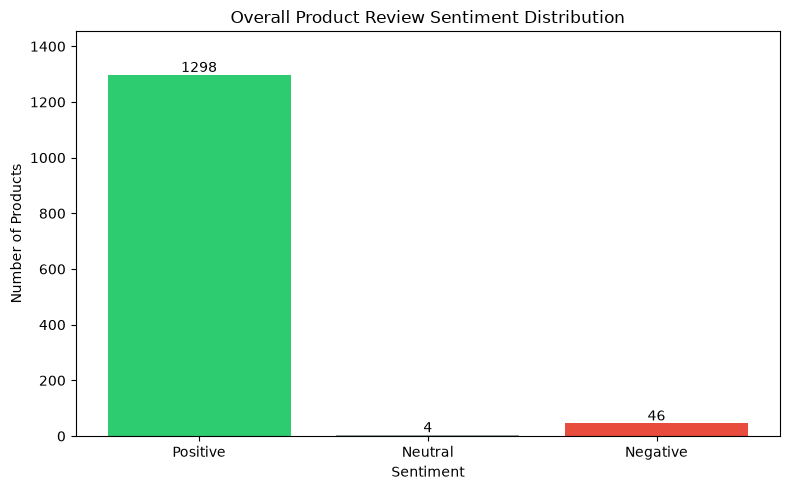

In [8]:
import matplotlib.pyplot as plt

sentiment_counts = (
    df["sentiment"]
    .value_counts()
    .reindex(["Positive", "Neutral", "Negative"], fill_value=0)
)

plt.figure(figsize=(8, 5))

bars = plt.bar(
    sentiment_counts.index,
    sentiment_counts.values,
    color=["#2ecc71", "#95a5a6", "#e74c3c"]
)

plt.title("Overall Product Review Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Products")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 10,
        str(int(height)),
        ha="center"
    )

plt.ylim(0, max(sentiment_counts.values) * 1.12)
plt.tight_layout()
plt.show()

In [9]:
# Extract main product category

df["main_category"] = (
    df["category"]
    .str.split("|", regex=False)
    .str[0]
    .str.strip()
)

# Check category-wise product counts
category_counts = df["main_category"].value_counts()

print("Total Categories:", df["main_category"].nunique())

print("\nCategory-wise Product Counts:")
print(category_counts)

Total Categories: 9

Category-wise Product Counts:
main_category
Electronics              490
Home&Kitchen             447
Computers&Accessories    373
OfficeProducts            31
MusicalInstruments         2
HomeImprovement            2
Toys&Games                 1
Car&Motorbike              1
Health&PersonalCare        1
Name: count, dtype: int64


In [10]:
# Sentiment counts for ALL 9 categories

category_sentiment = pd.crosstab(
    df["main_category"],
    df["sentiment"]
)

category_sentiment = category_sentiment.reindex(
    columns=["Positive", "Neutral", "Negative"],
    fill_value=0
)

# Percentage distribution
category_sentiment_pct = (
    category_sentiment
    .div(category_sentiment.sum(axis=1), axis=0)
    * 100
).round(2)

print("CATEGORY-WISE SENTIMENT COUNTS")
display(category_sentiment)

print("\nCATEGORY-WISE SENTIMENT PERCENTAGES")
display(category_sentiment_pct)

CATEGORY-WISE SENTIMENT COUNTS


sentiment,Positive,Neutral,Negative
main_category,,,
Car&Motorbike,1,0,0
Computers&Accessories,360,2,11
Electronics,472,1,17
Health&PersonalCare,1,0,0
Home&Kitchen,429,1,17
HomeImprovement,2,0,0
MusicalInstruments,2,0,0
OfficeProducts,30,0,1
Toys&Games,1,0,0



CATEGORY-WISE SENTIMENT PERCENTAGES


sentiment,Positive,Neutral,Negative
main_category,,,
Car&Motorbike,100.00,0.00,0.00
Computers&Accessories,96.51,0.54,2.95
Electronics,96.33,0.20,3.47
Health&PersonalCare,100.00,0.00,0.00
Home&Kitchen,95.97,0.22,3.80
HomeImprovement,100.00,0.00,0.00
MusicalInstruments,100.00,0.00,0.00
OfficeProducts,96.77,0.00,3.23
Toys&Games,100.00,0.00,0.00


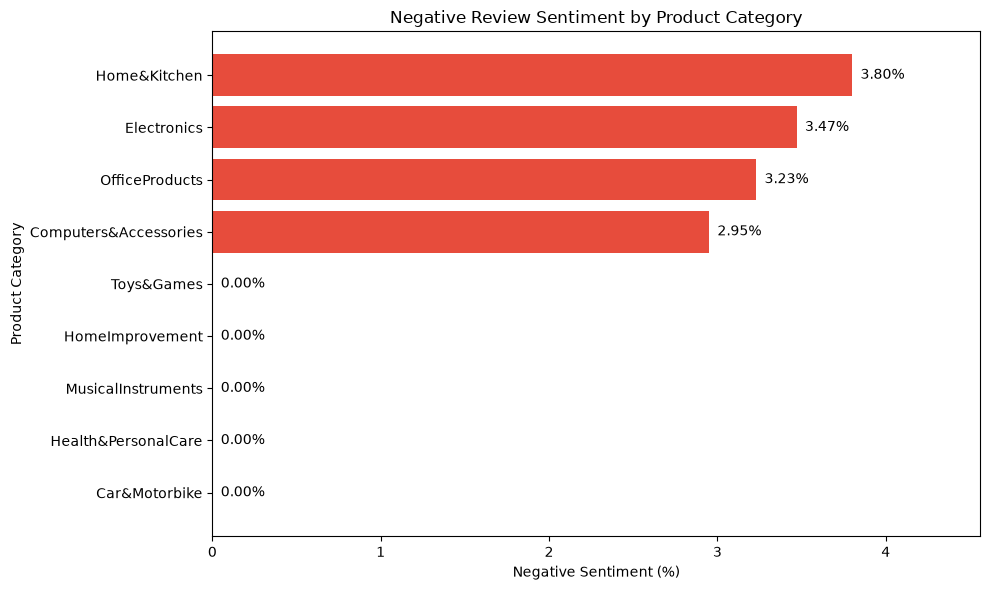

In [12]:
#all 9 categories sentiment chart
import matplotlib.pyplot as plt

negative_pct = category_sentiment_pct["Negative"].sort_values()

plt.figure(figsize=(10, 6))

bars = plt.barh(
    negative_pct.index,
    negative_pct.values,
    color="#e74c3c"
)

plt.title("Negative Review Sentiment by Product Category")
plt.xlabel("Negative Sentiment (%)")
plt.ylabel("Product Category")

plt.xlim(0, max(negative_pct.max() * 1.2, 1))

for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 0.05,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.2f}%",
        va="center"
    )

plt.tight_layout()
plt.show()

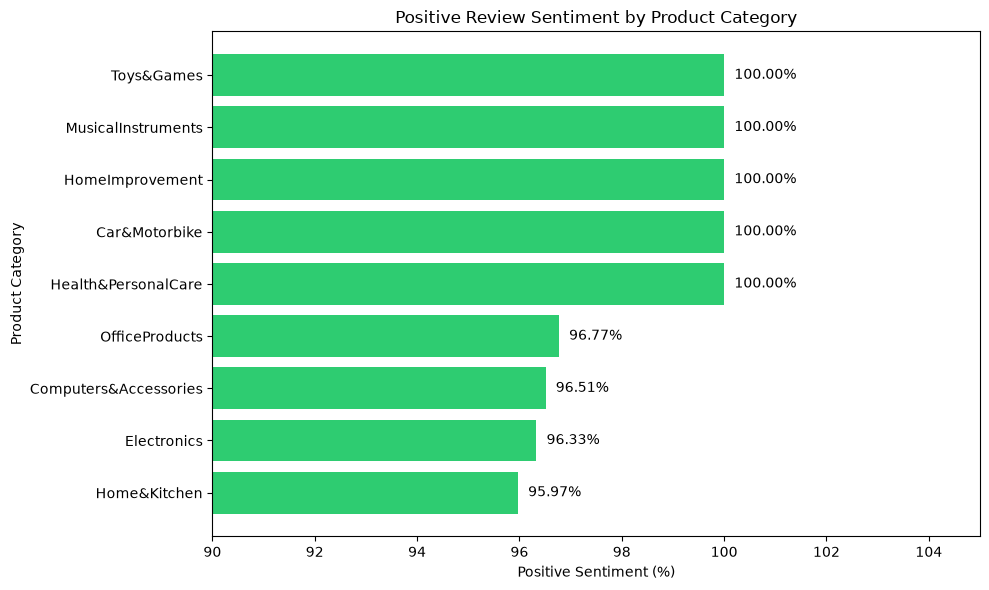

In [13]:
import matplotlib.pyplot as plt

# Sort categories by positive sentiment percentage
positive_pct = category_sentiment_pct["Positive"].sort_values()

plt.figure(figsize=(10, 6))

bars = plt.barh(
    positive_pct.index,
    positive_pct.values,
    color="#2ecc71"
)

plt.title("Positive Review Sentiment by Product Category")
plt.xlabel("Positive Sentiment (%)")
plt.ylabel("Product Category")

# Zoom into the range to show small differences
plt.xlim(90, 105)

for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 0.2,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.2f}%",
        va="center"
    )

plt.tight_layout()
plt.show()

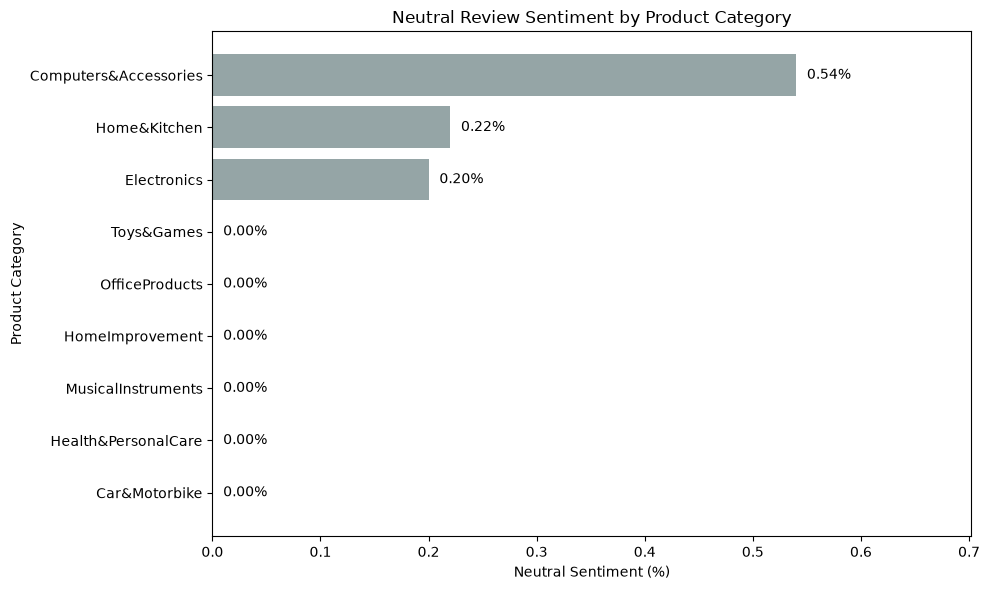

In [14]:
import matplotlib.pyplot as plt

# Sort categories by neutral sentiment percentage
neutral_pct = category_sentiment_pct["Neutral"].sort_values()

plt.figure(figsize=(10, 6))

bars = plt.barh(
    neutral_pct.index,
    neutral_pct.values,
    color="#95a5a6"
)

plt.title("Neutral Review Sentiment by Product Category")
plt.xlabel("Neutral Sentiment (%)")
plt.ylabel("Product Category")

plt.xlim(0, max(neutral_pct.max() * 1.3, 0.7))

# Display percentages on bars
for bar in bars:
    width = bar.get_width()

    plt.text(
        width + 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.2f}%",
        va="center"
    )

plt.tight_layout()
plt.show()

In [15]:
#statistical tests (chi-square)
from scipy.stats import chi2_contingency

# All 9 categories
chi2, p_value, dof, expected = chi2_contingency(
    category_sentiment
)

print("Chi-Square Statistic:", round(chi2, 4))
print("P-Value:", p_value)
print("Degrees of Freedom:", dof)

# Check expected frequencies
expected_below_5 = (expected < 5).sum()
total_cells = expected.size

print("\nExpected Frequencies Below 5:", expected_below_5)
print("Total Cells:", total_cells)

print(
    "Percentage Below 5:",
    round(expected_below_5 / total_cells * 100, 2),
    "%"
)

print("Minimum Expected Frequency:", round(expected.min(), 4))

Chi-Square Statistic: 1.7544
P-Value: 0.9999959974325877
Degrees of Freedom: 16

Expected Frequencies Below 5: 20
Total Cells: 27
Percentage Below 5: 74.07 %
Minimum Expected Frequency: 0.003


In [19]:
#montecarlo statistical test
import scipy
from scipy.stats import chi2_contingency, MonteCarloMethod

# Monte Carlo simulation with 10,000 resamples
mc_method = MonteCarloMethod(
    n_resamples=10000,
    rng=42
)

# Chi-Square test using Monte Carlo p-value
result = chi2_contingency(
    category_sentiment,
    correction=False,
    method=mc_method
)

print("Chi-Square Statistic:", round(result.statistic, 4))
print("Monte Carlo P-Value:", round(result.pvalue, 6))
print("failed to reject H0")

Chi-Square Statistic: 1.7544
Monte Carlo P-Value: 0.960704
failed to reject H0


In [20]:
# Top 10 products with strongest negative sentiment

top_negative_products = df.nsmallest(
    10, "sentiment_score"
)[
    [
        "product_name",
        "main_category",
        "rating",
        "sentiment_score",
        "sentiment"
    ]
]

print("TOP 10 MOST NEGATIVE PRODUCTS")
display(top_negative_products)

TOP 10 MOST NEGATIVE PRODUCTS


,product_name,main_category,rating,sentiment_score,sentiment
264,Realme Smart TV Stick 4K,Electronics,4.5,-0.9752,Negative
275,LOHAYA Voice Assistant Remote Compatible for A...,Electronics,3.3,-0.9726,Negative
1276,Bulfyss Plastic Sticky Lint Roller Hair Remove...,Home&Kitchen,3.5,-0.9557,Negative
989,Bajaj Deluxe 2000 Watts Halogen Room Heater (S...,Home&Kitchen,3.7,-0.9547,Negative
1208,Aquaguard Aura RO+UV+UF+Taste Adjuster(MTDS) w...,Home&Kitchen,4.0,-0.9377,Negative
924,"Morphy Richards OFR Room Heater, 09 Fin 2000 W...",Home&Kitchen,4.0,-0.9217,Negative
1055,KENT 16088 Vogue Electric Kettle 1.8 Litre 150...,Home&Kitchen,3.8,-0.9213,Negative
913,"Prestige 1.5 Litre Kettle 1500-watts, Red",Home&Kitchen,3.9,-0.9120,Negative
1224,Bajaj Majesty Duetto Gas 6 Ltr Vertical Water ...,Home&Kitchen,3.9,-0.9099,Negative
1001,IKEA Frother for Milk,Home&Kitchen,3.3,-0.9074,Negative


In [21]:
# High rating but negative review sentiment
high_rating_negative = df[
    (df["rating"] >= 4.0) &
    (df["sentiment"] == "Negative")
]

# Low rating but positive review sentiment
low_rating_positive = df[
    (df["rating"] <= 3.5) &
    (df["sentiment"] == "Positive")
]

print("High Rating + Negative Sentiment:",
      len(high_rating_negative))

print("Low Rating + Positive Sentiment:",
      len(low_rating_positive))

print("\nHIGH RATING + NEGATIVE SENTIMENT")
display(
    high_rating_negative[
        ["product_name", "rating", "sentiment_score"]
    ].head(10)
)

print("\nLOW RATING + POSITIVE SENTIMENT")
display(
    low_rating_positive[
        ["product_name", "rating", "sentiment_score"]
    ].head(10)
)

High Rating + Negative Sentiment: 18
Low Rating + Positive Sentiment: 54

HIGH RATING + NEGATIVE SENTIMENT


,product_name,rating,sentiment_score
22,Samsung 80 cm (32 Inches) Wondertainment Serie...,4.3,-0.5898
38,OnePlus 126 cm (50 inches) Y Series 4K Ultra H...,4.2,-0.7564
85,OnePlus 108 cm (43 inches) Y Series 4K Ultra H...,4.2,-0.7564
126,AmazonBasics 3 Feet High Speed HDMI Male to Fe...,4.3,-0.6499
134,AmazonBasics New Release ABS USB-A to Lightnin...,4.2,-0.4019
152,Samsung 80 cm (32 inches) Wondertainment Serie...,4.3,-0.5898
155,7SEVEN® Compatible for Tata Sky Remote Origina...,4.3,-0.7917
264,Realme Smart TV Stick 4K,4.5,-0.9752
286,Storite Super Speed USB 3.0 Male to Male Cable...,4.3,-0.4118
490,"Newly Launched Boult Dive+ with 1.85"" HD Displ...",4.3,-0.8268



LOW RATING + POSITIVE SENTIMENT


,product_name,rating,sentiment_score
82,SKYWALL 81.28 cm (32 inches) HD Ready Smart LE...,3.4,0.9755
117,King Shine Multi Retractable 3.0A Fast Charger...,3.5,0.8386
142,LRIPL Mi Remote Control with Netflix & Prime V...,3.2,0.9726
154,GENERIC Ultra-Mini Bluetooth CSR 4.0 USB Dongl...,3.4,0.9850
179,7SEVEN® Bluetooth Voice Command Remote for Xia...,3.3,0.9343
211,7SEVEN® Compatible Tata Sky Remote Control Rep...,3.5,0.9121
233,LOHAYA LCD/LED Remote Compatible for Sony Brav...,3.5,0.6712
236,7SEVEN® TCL Remote Control Smart TV RC802V Rem...,3.4,0.9749
283,Tata Sky Digital TV HD Setup Box Remote,3.5,0.8928
289,Firestick Remote,3.3,0.8896


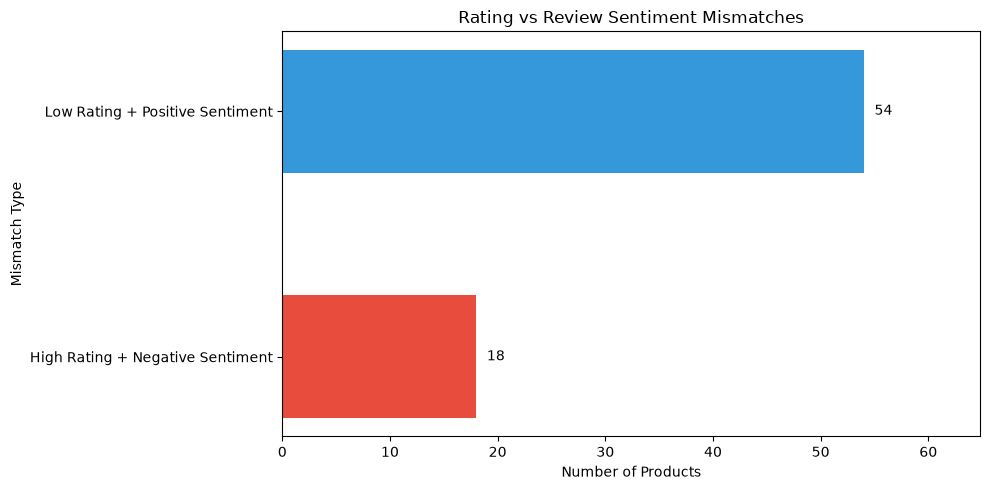

In [22]:
import matplotlib.pyplot as plt

mismatch_types = [
    "High Rating + Negative Sentiment",
    "Low Rating + Positive Sentiment"
]

mismatch_counts = [
    len(high_rating_negative),
    len(low_rating_positive)
]

plt.figure(figsize=(10, 5))

bars = plt.barh(
    mismatch_types,
    mismatch_counts,
    color=["#e74c3c", "#3498db"],
    height=0.5
)

plt.title("Rating vs Review Sentiment Mismatches")
plt.xlabel("Number of Products")
plt.ylabel("Mismatch Type")

plt.xlim(0, max(mismatch_counts) * 1.2)

for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 1,
        bar.get_y() + bar.get_height() / 2,
        str(int(width)),
        va="center"
    )

plt.tight_layout()
plt.show()

In [23]:
# Select important columns for final sentiment analysis

sentiment_export = df[
    [
        "product_name",
        "main_category",
        "rating",
        "review_title",
        "review_content",
        "clean_review_title",
        "clean_review_content",
        "sentiment_score",
        "sentiment",
        "avg_title_sentiment"
    ]
].copy()

# Save analysis results
sentiment_export.to_csv(
    "task_3_sentiment_analysis.csv",
    index=False
)

print("CSV exported successfully!")
print("Total products:", len(sentiment_export))
print("Total columns:", len(sentiment_export.columns))

CSV exported successfully!
Total products: 1348
Total columns: 10


In [24]:
# Identify strongly negative products
strong_negative = df[
    df["sentiment_score"] <= -0.50
].copy()

print("Strongly Negative Products:", len(strong_negative))

print("\nCategory-wise Strong Negative Products:")
print(
    strong_negative["main_category"].value_counts()
)

print("\nTop 10 Strongly Negative Products:")
display(
    strong_negative.sort_values("sentiment_score")[
        ["product_name", "main_category", "rating", "sentiment_score"]
    ].head(10)
)

Strongly Negative Products: 32

Category-wise Strong Negative Products:
main_category
Electronics              14
Home&Kitchen             14
Computers&Accessories     4
Name: count, dtype: int64

Top 10 Strongly Negative Products:


,product_name,main_category,rating,sentiment_score
264,Realme Smart TV Stick 4K,Electronics,4.5,-0.9752
275,LOHAYA Voice Assistant Remote Compatible for A...,Electronics,3.3,-0.9726
1276,Bulfyss Plastic Sticky Lint Roller Hair Remove...,Home&Kitchen,3.5,-0.9557
989,Bajaj Deluxe 2000 Watts Halogen Room Heater (S...,Home&Kitchen,3.7,-0.9547
1208,Aquaguard Aura RO+UV+UF+Taste Adjuster(MTDS) w...,Home&Kitchen,4.0,-0.9377
924,"Morphy Richards OFR Room Heater, 09 Fin 2000 W...",Home&Kitchen,4.0,-0.9217
1055,KENT 16088 Vogue Electric Kettle 1.8 Litre 150...,Home&Kitchen,3.8,-0.9213
913,"Prestige 1.5 Litre Kettle 1500-watts, Red",Home&Kitchen,3.9,-0.9120
1224,Bajaj Majesty Duetto Gas 6 Ltr Vertical Water ...,Home&Kitchen,3.9,-0.9099
1001,IKEA Frother for Milk,Home&Kitchen,3.3,-0.9074


In [25]:
print("========== TASK 3 FINAL SUMMARY ==========")

print("Total Products:", len(df))
print("Total Categories:", df["main_category"].nunique())

print("\nSentiment Distribution:")
print(df["sentiment"].value_counts())

print("\nStrongly Negative Products:",
      len(df[df["sentiment_score"] <= -0.50]))

print("\nHigh Rating + Negative Sentiment:",
      len(high_rating_negative))

print("Low Rating + Positive Sentiment:",
      len(low_rating_positive))

print("\nCategory-wise Negative Sentiment (%):")
print(
    category_sentiment_pct["Negative"]
    .sort_values(ascending=False)
)

========== TASK 3 FINAL SUMMARY ==========
Total Products: 1348
Total Categories: 9

Sentiment Distribution:
sentiment
Positive    1298
Negative      46
Neutral        4
Name: count, dtype: int64

Strongly Negative Products: 32

High Rating + Negative Sentiment: 18
Low Rating + Positive Sentiment: 54

Category-wise Negative Sentiment (%):
main_category
Home&Kitchen             3.80
Electronics              3.47
OfficeProducts           3.23
Computers&Accessories    2.95
Car&Motorbike            0.00
Health&PersonalCare      0.00
HomeImprovement          0.00
MusicalInstruments       0.00
Toys&Games               0.00
Name: Negative, dtype: float64


## Conclusion — Review-Based Sentiment Analysis

This analysis examined customer review sentiment across **1,348 Amazon products belonging to 9 categories** using the VADER sentiment analysis model.

### Key Findings

1. **Overall Sentiment:** Out of 1,348 products, 1,298 (96.29%) were classified as Positive, 46 (3.41%) as Negative, and 4 (0.30%) as Neutral based on their combined review text.

2. **Individual Review Titles:** Analysis of 11,189 review-title segments showed 68.57% Positive, 23.79% Neutral, and 7.64% Negative sentiment, highlighting differences between short review titles and aggregated review content.

3. **Category-Wise Analysis:** Home & Kitchen recorded the highest negative sentiment percentage (3.80%) among the major product categories. Electronics and Home & Kitchen each contained 17 negatively classified products.

4. **Statistical Testing:** A Chi-Square Test of Independence using Monte Carlo simulation found no statistically significant association between product category and sentiment (χ² = 1.7544, p = 0.9607). Therefore, the null hypothesis was not rejected at the 5% significance level.

5. **Rating–Sentiment Mismatches:** A total of 72 potential mismatches were identified: 18 products had high numerical ratings (≥ 4.0) but negative review sentiment, while 54 products had lower ratings (≤ 3.5) but positive review sentiment.

### Limitations

The dataset contains multiple customer reviews combined into individual product records. Consequently, sentiment scores represent aggregated review text rather than individual customer opinions. Long reviews may also produce extreme VADER scores. Additionally, very small category sample sizes limit category-level comparisons.

### Final Business Insight

Customer review sentiment provides useful qualitative insights beyond numerical ratings. Combining sentiment analysis with product ratings can help businesses identify potentially dissatisfied customers, investigate product-quality concerns, and prioritize products for further review. However, sentiment predictions should be interpreted cautiously and validated against the original review text before making business decisions.